# Notebook 02 — Preprocessing, Feature Selection, Modeling, dan Evaluasi

Notebook ini memuat ulang data secara mandiri sehingga dapat dijalankan terpisah. Jalankan seluruh sel secara berurutan.

In [1]:
# Impor pustaka
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

print("Pustaka berhasil diimpor.")


Pustaka berhasil diimpor.


In [2]:
# Memuat dataset dari satu lokasi standar di root proyek.
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
raw_dir = ROOT / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)
data_path = raw_dir / "student-mat.csv"
if not data_path.exists():
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = raw_dir / "student-performance.zip"
    try:
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, "r") as zf:
            member = next((m for m in zf.namelist() if m.endswith("student-mat.csv")), None)
            if member is None:
                raise FileNotFoundError("student-mat.csv tidak ditemukan di arsip UCI.")
            data_path.write_bytes(zf.read(member))
    except Exception as e:
        raise RuntimeError(
            f"Dataset tidak tersedia di {data_path} dan unduhan UCI gagal. "
            "Letakkan student-mat.csv di folder data/raw/."
        ) from e

df_raw = pd.read_csv(data_path, sep=";")
print("Sumber data:", data_path)
print("Ukuran data:", df_raw.shape)
display(df_raw.head())

Sumber data: c:\Users\LENOVO\OneDrive\Documents\Tugas Yasmine\Data Science\Proyek_Akhir_Data_Science_Student_Performance_Diperbaiki\Proyek_Akhir_Data_Science_Student_Performance\data\raw\student-mat.csv
Ukuran data: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


### 2.1 Memahami struktur data
Dataset Matematika umumnya memuat 395 baris dan 33 kolom, termasuk atribut demografis, keluarga, sekolah, dan tiga nilai periode (`G1`, `G2`, `G3`). Pemeriksaan di bawah menampilkan kondisi berkas yang benar-benar dimuat, sehingga perbedaan versi atau berkas dapat terdeteksi.


## 4. Cleaning dan Preprocessing

### 4.1 Pemeriksaan dan penanganan
Tahap ini memeriksa duplikasi, nilai kosong, tipe data, dan rentang target. Dataset UCI didokumentasikan tidak memiliki missing value, tetapi pengecekan tetap dilakukan pada berkas yang dimuat. Baris duplikat penuh dihapus bila ada. Nilai ekstrem tidak dihapus otomatis karena bisa merupakan observasi valid.


In [3]:
# Salin data agar data asli tetap tersedia untuk audit
df = df_raw.copy()
shape_before = df.shape
missing_before = int(df.isna().sum().sum())
duplicates_before = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

# Pastikan target berupa numerik dan periksa baris dengan target tidak valid
df["G3"] = pd.to_numeric(df["G3"], errors="coerce")
invalid_target = df["G3"].isna() | ~df["G3"].between(0, 20)
invalid_target_count = int(invalid_target.sum())
df = df.loc[~invalid_target].copy()

print("Sebelum cleaning:", shape_before)
print("Missing sebelum:", missing_before)
print("Duplikat sebelum:", duplicates_before)
print("Target tidak valid yang dihapus:", invalid_target_count)
print("Sesudah cleaning:", df.shape)
print("Missing sesudah:", int(df.isna().sum().sum()))
print("Duplikat sesudah:", int(df.duplicated().sum()))


Sebelum cleaning: (395, 33)
Missing sebelum: 0
Duplikat sebelum: 0
Target tidak valid yang dihapus: 0
Sesudah cleaning: (395, 33)
Missing sesudah: 0
Duplikat sesudah: 0


### 4.2 Memeriksa nilai ekstrem
Outlier diperiksa pada `absences` dengan aturan IQR. Pemeriksaan ini hanya menandai kandidat outlier; nilai tidak dihapus secara otomatis karena jumlah ketidakhadiran yang tinggi mungkin benar-benar terjadi.


In [4]:
if "absences" in df.columns:
    q1 = df["absences"].quantile(0.25)
    q3 = df["absences"].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df["absences"] < lower_bound) | (df["absences"] > upper_bound)

    print(f"Batas IQR: {lower_bound:.2f} sampai {upper_bound:.2f}")
    print("Jumlah kandidat outlier absences:", int(outlier_mask.sum()))
    display(df.loc[outlier_mask, ["absences", "G3"]].sort_values("absences", ascending=False).head(15))


Batas IQR: -12.00 sampai 20.00
Jumlah kandidat outlier absences: 15


,absences,G3
276,75,9
183,56,8
74,54,11
315,40,11
307,38,8
280,30,8
205,28,9
103,26,6
40,25,11
198,24,18


### 4.3 Feature selection dan pembagian data
`G3` menjadi target. `G1` dan `G2` dikeluarkan karena merupakan nilai periode sebelumnya yang sangat dekat dengan target dan dapat membuat tugas prediksi menjadi lebih mudah tetapi kurang berguna untuk perkiraan berbasis fitur non-nilai. Kolom identitas tidak tersedia pada skema ini. Data dibagi menjadi data latih dan data uji sebelum proses preprocessing dipelajari, sehingga statistik transformasi tidak bocor dari data uji.


In [5]:
target_col = "G3"
excluded_cols = [c for c in ["G1", "G2", target_col] if c in df.columns]
X = df.drop(columns=excluded_cols)
y = df[target_col].astype(float)

# Kenali fitur kategorikal berdasarkan tipe object/category.
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Jumlah fitur:", X.shape[1])
print("Fitur kategorikal:", categorical_features)
print("Fitur numerik/ordinal:", numeric_features)
print("Fitur yang dikeluarkan:", excluded_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("\nUkuran train:", X_train.shape, "| Ukuran test:", X_test.shape)


Jumlah fitur: 30
Fitur kategorikal: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Fitur numerik/ordinal: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Fitur yang dikeluarkan: ['G1', 'G2', 'G3']

Ukuran train: (316, 30) | Ukuran test: (79, 30)


### 4.4 Pipeline preprocessing
Fitur numerik diimputasi dengan median jika ada nilai kosong, lalu distandardisasi. Fitur kategorikal diimputasi dengan modus dan dikodekan menggunakan One-Hot Encoding. Semua transformasi dipasang di dalam pipeline model agar hanya belajar dari data latih. Standardisasi bermanfaat untuk regresi linear; pipeline yang sama juga memudahkan pembandingan model.


In [6]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Pipeline preprocessing siap.")


Pipeline preprocessing siap.


## 5. Modelling

Model pembanding yang digunakan adalah:
1. **Dummy Regressor:** baseline yang selalu memperkirakan rata-rata target pada data latih.
2. **Linear Regression:** model regresi linear sebagai pendekatan sederhana.
3. **Random Forest Regressor:** gabungan pohon keputusan yang dapat menangkap pola non-linear.

Pastikan model yang dipilih sesuai dengan model yang sudah dibahas dalam materi praktikum. Jika Random Forest belum termasuk materi, ganti dengan metode yang telah diajarkan.


In [7]:
models = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        min_samples_leaf=2
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: training selesai")


Baseline (Mean): training selesai
Linear Regression: training selesai
Random Forest: training selesai


## 6. Evaluasi Model

Evaluasi dilakukan pada data uji yang tidak digunakan untuk melatih model. MAE menunjukkan rata-rata besar kesalahan absolut dalam satuan poin nilai; RMSE memberi penalti lebih besar pada kesalahan besar; R² mengukur proporsi variasi target yang dijelaskan model dibandingkan baseline rata-rata pada data uji.


In [8]:
results = []
predictions = {}

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}"}))


,Model,MAE,RMSE,R2
0,Random Forest,3.041,3.804,0.294
1,Linear Regression,3.395,4.196,0.141
2,Baseline (Mean),3.646,4.550,-0.010


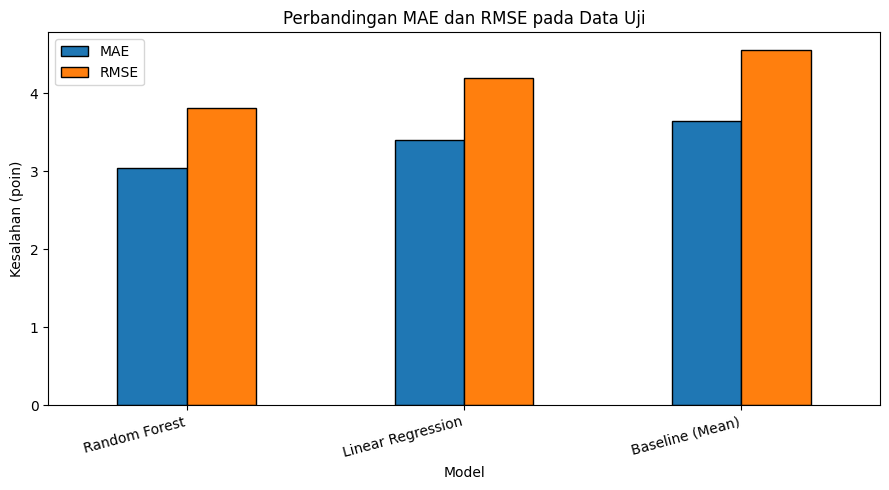

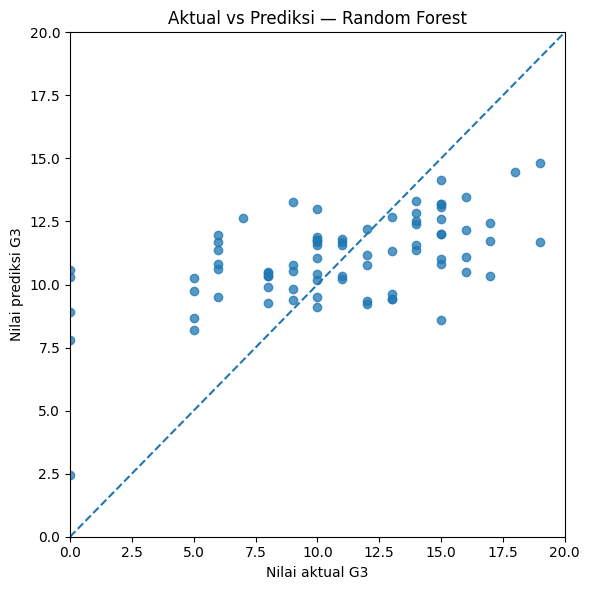

Model dengan RMSE terendah pada split ini: Random Forest


In [9]:
# Grafik perbandingan MAE dan RMSE
plot_df = results_df.set_index("Model")[["MAE", "RMSE"]]
plot_df.plot(kind="bar", figsize=(9, 5), edgecolor="black")
plt.title("Perbandingan MAE dan RMSE pada Data Uji")
plt.ylabel("Kesalahan (poin)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# Perbandingan nilai aktual dengan prediksi untuk model dengan RMSE terendah
best_model_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.75)
plt.plot([0, 20], [0, 20], linestyle="--")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Nilai aktual G3")
plt.ylabel("Nilai prediksi G3")
plt.title(f"Aktual vs Prediksi — {best_model_name}")
plt.tight_layout()
plt.show()

print("Model dengan RMSE terendah pada split ini:", best_model_name)


### 6.1 Validasi silang
Satu kali pembagian train-test dapat dipengaruhi komposisi data. Validasi silang 5-fold pada data latih memberi gambaran kestabilan model. Pipeline memastikan preprocessing dilakukan ulang di setiap fold. Skor yang dilaporkan berupa MAE, RMSE, dan R².


,Model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
0,Random Forest,2.938,0.296,3.930,0.292,0.209,0.149
1,Baseline (Mean),3.403,0.629,4.563,0.634,-0.035,0.047
2,Linear Regression,3.523,0.382,4.607,0.327,-0.092,0.223


Model terpilih berdasarkan CV RMSE: Random Forest
Evaluasi akhir pada data uji yang tidak digunakan untuk pemilihan model:


,Model,MAE,RMSE,R2
0,Random Forest,3.041,3.804,0.294


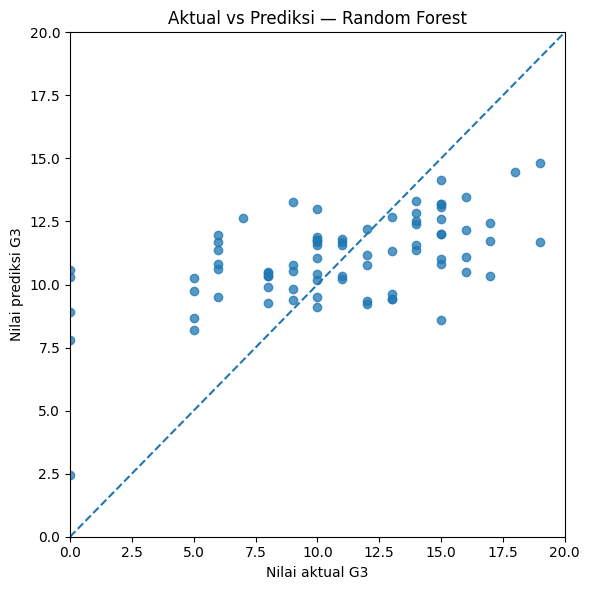

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring,
        return_train_score=False
    )
    rmse_scores = np.sqrt(-scores["test_mse"])
    cv_rows.append({
        "Model": name,
        "CV_MAE_mean": -scores["test_mae"].mean(),
        "CV_MAE_std": scores["test_mae"].std(),
        "CV_RMSE_mean": rmse_scores.mean(),
        "CV_RMSE_std": rmse_scores.std(),
        "CV_R2_mean": scores["test_r2"].mean(),
        "CV_R2_std": scores["test_r2"].std()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV_RMSE_mean").reset_index(drop=True)
display(cv_results_df.style.format({
    col: "{:.3f}" for col in cv_results_df.columns if col != "Model"
}))


# Pemilihan model dilakukan berdasarkan RMSE rata-rata validasi silang pada data latih.
best_model_name = cv_results_df.iloc[0]["Model"]
best_model = pipelines[best_model_name]
best_model.fit(X_train, y_train)
best_pred = best_model.predict(X_test)
final_model_results = {
    "Model": best_model_name,
    "MAE": mean_absolute_error(y_test, best_pred),
    "RMSE": mean_squared_error(y_test, best_pred) ** 0.5,
    "R2": r2_score(y_test, best_pred),
}
print("Model terpilih berdasarkan CV RMSE:", best_model_name)
print("Evaluasi akhir pada data uji yang tidak digunakan untuk pemilihan model:")
display(pd.DataFrame([final_model_results]).style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}"}))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.75)
plt.plot([0, 20], [0, 20], linestyle="--")
plt.xlim(0, 20); plt.ylim(0, 20)
plt.xlabel("Nilai aktual G3"); plt.ylabel("Nilai prediksi G3")
plt.title(f"Aktual vs Prediksi — {best_model_name}")
plt.tight_layout(); plt.show()


### 6.2 Feature importance
Untuk menjelaskan fitur yang paling memengaruhi kinerja prediksi, permutation importance dihitung pada data uji. Nilai menunjukkan perubahan skor model ketika suatu fitur diacak; nilai lebih besar menunjukkan bahwa model lebih bergantung pada fitur tersebut. Ini bukan bukti bahwa fitur menyebabkan perubahan nilai.


,Fitur,Importance_mean,Importance_std
14,failures,0.4767,0.1531
29,absences,0.3397,0.1610
1,sex,0.1133,0.0315
25,goout,0.0858,0.0323
15,schoolsup,0.0569,0.0360
6,Medu,0.0539,0.0206
11,guardian,0.0523,0.0332
8,Mjob,0.0433,0.0269
22,romantic,0.0431,0.0276
10,reason,0.0397,0.0293


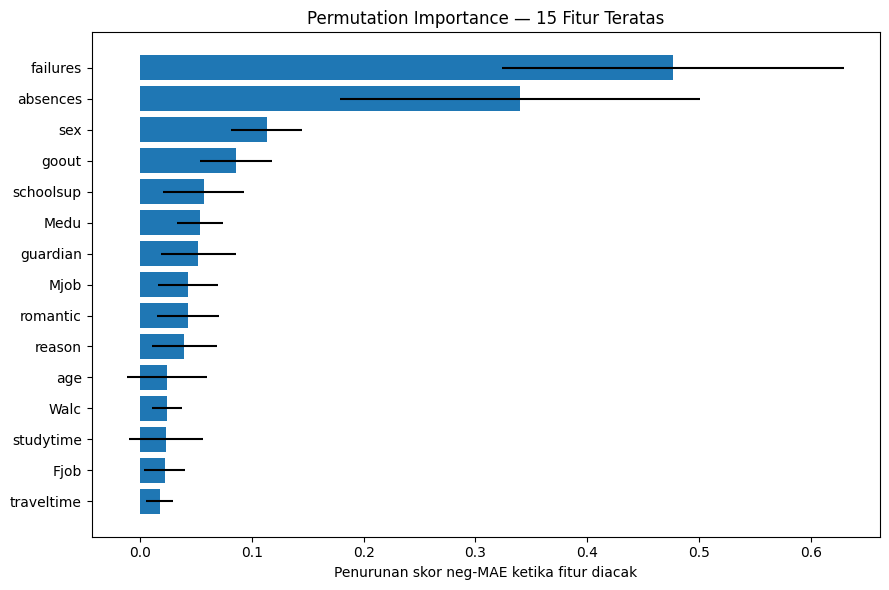

In [11]:
# Gunakan model yang dipilih dari validasi silang dan telah dilatih pada seluruh data latih
best_model = pipelines[best_model_name]
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=15,
    random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Fitur": X_test.columns,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std
}).sort_values("Importance_mean", ascending=False)

display(importance_df.head(15).style.format({
    "Importance_mean": "{:.4f}",
    "Importance_std": "{:.4f}"
}))

top_features = importance_df.head(15).sort_values("Importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Fitur"], top_features["Importance_mean"], xerr=top_features["Importance_std"])
plt.xlabel("Penurunan skor neg-MAE ketika fitur diacak")
plt.title("Permutation Importance — 15 Fitur Teratas")
plt.tight_layout()
plt.show()


## 7. Konklusi Otomatis dan Keterbatasan

Sel berikut membuat ringkasan awal berdasarkan hasil aktual notebook. Setelah dijalankan, periksa apakah kesimpulan sesuai dengan tabel dan grafik, lalu tambahkan interpretasi kelompok sendiri.


In [12]:
best_row = pd.Series(final_model_results)
print("RINGKASAN HASIL")
print(f"- Model terpilih berdasarkan validasi silang: {best_row['Model']}")
print(f"- MAE: {best_row['MAE']:.3f} poin")
print(f"- RMSE: {best_row['RMSE']:.3f} poin")
print(f"- R²: {best_row['R2']:.3f}")

print("\nINTERPRETASI")
print(
    f"MAE sebesar {best_row['MAE']:.2f} berarti rata-rata jarak absolut antara "
    "nilai aktual dan prediksi pada data uji sekitar angka tersebut dalam skala nilai G3."
)
print(
    "Bandingkan hasil model dengan baseline. R² dapat bernilai negatif jika model lebih buruk "
    "daripada prediksi menggunakan rata-rata target pada data evaluasi."
)

print("\nKETERBATASAN")
print("- Data berasal dari dua sekolah di Portugal sehingga generalisasi ke populasi lain terbatas.")
print("- Data relatif kecil; hasil dapat berubah karena pembagian data.")
print("- Fitur yang tersedia tidak membuktikan hubungan sebab-akibat.")
print("- G1 dan G2 sengaja dikeluarkan; hal ini membuat prediksi lebih menantang.")
print("- Makna khusus G3=0 perlu diperiksa dengan hati-hati; notebook ini tidak otomatis menghapusnya.")
print("- Kesesuaian model perlu dikonfirmasi dengan materi praktikum.")


RINGKASAN HASIL
- Model terpilih berdasarkan validasi silang: Random Forest
- MAE: 3.041 poin
- RMSE: 3.804 poin
- R²: 0.294

INTERPRETASI
MAE sebesar 3.04 berarti rata-rata jarak absolut antara nilai aktual dan prediksi pada data uji sekitar angka tersebut dalam skala nilai G3.
Bandingkan hasil model dengan baseline. R² dapat bernilai negatif jika model lebih buruk daripada prediksi menggunakan rata-rata target pada data evaluasi.

KETERBATASAN
- Data berasal dari dua sekolah di Portugal sehingga generalisasi ke populasi lain terbatas.
- Data relatif kecil; hasil dapat berubah karena pembagian data.
- Fitur yang tersedia tidak membuktikan hubungan sebab-akibat.
- G1 dan G2 sengaja dikeluarkan; hal ini membuat prediksi lebih menantang.
- Makna khusus G3=0 perlu diperiksa dengan hati-hati; notebook ini tidak otomatis menghapusnya.
- Kesesuaian model perlu dikonfirmasi dengan materi praktikum.


## 8. Referensi

1. Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T
2. UCI Machine Learning Repository. *Student Performance*. https://archive.ics.uci.edu/dataset/320/student%2Bperformance
3. Panduan Proyek Akhir Praktikum Data Science 2026/2027, Program Studi Informatika, UPN “Veteran” Yogyakarta.
